# Задание 50. Логистическая регрессия на данных RemI AI

## 1. Данные и задача

По первым четырём ответам предположим, покажет ли дополнительная проверка затруднение с производными. Берём те же 3000 вымышленных студентов, что использовали в промежуточной аттестации и задании 47.

Целевая переменная — `needs_review`. Значение 1 означает не больше одного правильного ответа из трёх на дополнительной проверке, 0 — два или три. Это учебное правило. Признаки — число правильных начальных ответов по уравнениям и производным, по два вопроса на каждую тему.

Все ответы созданы программой. Зависимость между начальными и дополнительными ответами заложена при моделировании. Для прогноза берём только начальные ответы.

Для запуска нужны pandas, numpy, matplotlib и scikit-learn. Таблица `diagnostic_data.csv` лежит рядом с блокнотом.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

path = Path("diagnostic_data.csv")
if not path.is_file():
    path = Path("cleaned.csv")
data = pd.read_csv(path)
features = ["initial_equations_correct", "initial_derivatives_correct"]
X = data[features]
y = data["needs_review"]

print(f"Сессий: {len(data)}, доля класса 1: {y.mean():.3f}")
assert data["session_id"].is_unique
assert not data[features + ["needs_review"]].isna().any().any()
assert (y == (data["followup_correct"] <= 1).astype(int)).all()
display(data.groupby(features)["needs_review"].agg(["size", "mean"]).round(3))

Сессий: 3000, доля класса 1: 0.506


size   mean
initial_equations_correct initial_derivatives_correct             
0                         0                             395  0.775
                          1                             374  0.612
                          2                             184  0.397
1                         0                             405  0.721
                          1                             579  0.520
                          2                             433  0.256
2                         0                             107  0.523
                          1                             237  0.376
                          2                             286  0.210

## 2. Обучающая, проверочная и тестовая выборки

Повторяем разбиение задания 47. Получаем 1800 сессий для обучения, 600 для выбора порога и 600 для теста. `stratify` сохраняет примерно одинаковые доли классов в каждой части.

Приводим признаки к сопоставимому масштабу. Среднее и стандартное отклонение определяем по обучающей части, затем применяем то же преобразование к остальным данным.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

scaler = StandardScaler()
fit_scaled = scaler.fit_transform(X_fit)
val_scaled = scaler.transform(X_val)
test_scaled = scaler.transform(X_test)

print(f"Обучение: {len(X_fit)}, проверка: {len(X_val)}, тест: {len(X_test)}")

Обучение: 1800, проверка: 600, тест: 600


## 3. Обучение модели и выбор порога

Логистическая регрессия оценивает вероятность класса 1. Обучаем модель с обычной L2-регуляризацией и `C = 1`.

Выбираем порог по наибольшему F1 на проверочной выборке. F1 учитывает и долю найденных затруднений, и долю верных положительных прогнозов. Стоимость разных ошибок отдельно не задана. При равном F1 берём порог с большей precision, затем первый по возрастанию порог.

Если вероятность не меньше выбранного порога, прогнозируем 1.

In [3]:
model = LogisticRegression(C=1.0, max_iter=1000)
model.fit(fit_scaled, y_fit)
val_probability = model.predict_proba(val_scaled)[:, 1]

rows = []
for threshold in sorted(set(val_probability)):
    predicted = (val_probability >= threshold).astype(int)
    rows.append({
        "Порог": threshold,
        "Precision": precision_score(y_val, predicted, zero_division=0),
        "Recall": recall_score(y_val, predicted),
        "F1": f1_score(y_val, predicted),
    })

thresholds = pd.DataFrame(rows).sort_values(
    ["F1", "Precision"], ascending=False, kind="stable"
)
display(thresholds.round(4))
best = thresholds.iloc[0]
threshold = float(best["Порог"])
print(f"Выбранный порог: {threshold:.4f}")

,Порог,Precision,Recall,F1
2,0.3608,0.5815,0.8713,0.6975
3,0.4044,0.5892,0.8284,0.6886
1,0.2795,0.5335,0.9472,0.6825
4,0.4970,0.6199,0.7591,0.6825
0,0.2105,0.5050,1.0000,0.6711
5,0.5897,0.7031,0.5941,0.6440
6,0.6336,0.7207,0.4257,0.5353
7,0.7155,0.7455,0.4059,0.5256
8,0.7854,0.8000,0.1848,0.3003


Выбранный порог: 0.3608


## 4. Precision–Recall и ROC

Строим кривые на проверочной выборке по вероятностям модели. На Precision–Recall отмечаем выбранный порог. ROC показывает долю найденных затруднений при разных долях ложных срабатываний. ROC-AUC считаем по вероятностям.

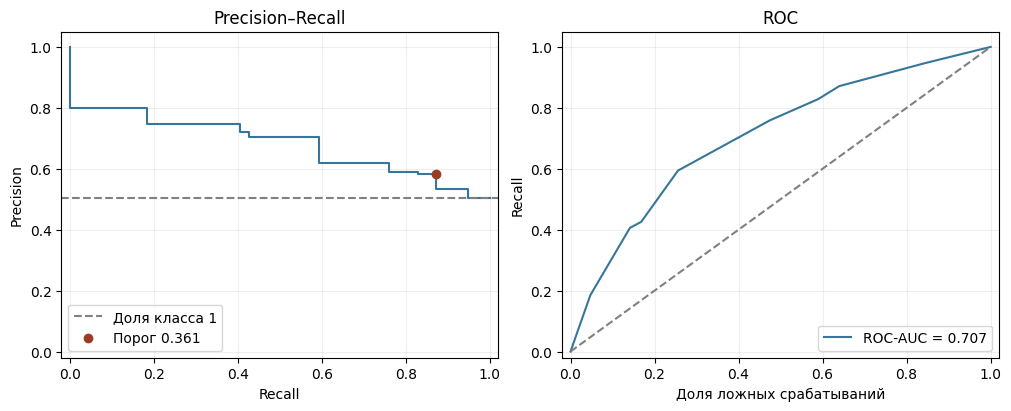

In [4]:
precision, recall, _ = precision_recall_curve(y_val, val_probability)
fpr, tpr, _ = roc_curve(y_val, val_probability)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].step(recall, precision, where="post", color="#37769a")
axes[0].axhline(y_val.mean(), color="gray", linestyle="--", label="Доля класса 1")
axes[0].scatter(best["Recall"], best["Precision"], color="#9b3c24",
                label=f"Порог {threshold:.3f}", zorder=3)
axes[0].set(title="Precision–Recall", xlabel="Recall", ylabel="Precision")
axes[0].legend(loc="lower left")

axes[1].plot(fpr, tpr, color="#37769a",
             label=f"ROC-AUC = {roc_auc_score(y_val, val_probability):.3f}")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set(title="ROC", xlabel="Доля ложных срабатываний", ylabel="Recall")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.grid(alpha=0.2)
plt.show()

## 5. Прогноз на тесте и сравнение с KNN

Применяем выбранный порог к тестовой выборке. Для сравнения воспроизводим KNN из задания 47 с 5 соседями и порогом 0,2. Обе модели обучены на одинаковых 1800 сессиях и проверяются на одинаковых 600 тестовых сессиях. Добавим простой прогноз самым частым классом.

Accuracy — доля верных прогнозов. Precision — доля настоящих затруднений среди положительных прогнозов. Recall — доля найденных затруднений среди всех фактических. F1 объединяет precision и recall. ROC-AUC оценивает ранжирование по вероятности.

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Логистическая регрессия,0.6367,0.5934,0.8911,0.7124,0.7288
KNN из задания 47,0.6367,0.5934,0.8911,0.7124,0.7224
Самый частый класс,0.5050,0.5050,1.0000,0.6711,0.5000


,Факт,Вероятность класса 1,Прогноз
2123,0,0.211,0
2811,1,0.785,1
1815,1,0.634,1
2364,0,0.497,1
454,1,0.497,1


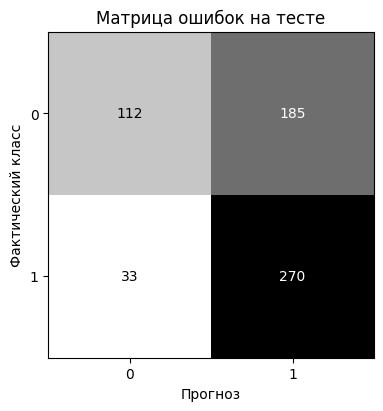

Найдено затруднений: 270, пропущено: 33
Ложных срабатываний: 185, верно определён класс 0: 112


In [5]:
test_probability = model.predict_proba(test_scaled)[:, 1]
test_prediction = (test_probability >= threshold).astype(int)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(fit_scaled, y_fit)
knn_probability = knn.predict_proba(test_scaled)[:, 1]
knn_prediction = (knn_probability >= 0.2).astype(int)
majority = int(y_fit.mode().iloc[0])

metrics = []
for name, predicted, probability in [
    ("Логистическая регрессия", test_prediction, test_probability),
    ("KNN из задания 47", knn_prediction, knn_probability),
    ("Самый частый класс", [majority] * len(y_test), [float(majority)] * len(y_test)),
]:
    metrics.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted),
        "F1": f1_score(y_test, predicted),
        "ROC-AUC": roc_auc_score(y_test, probability),
    })

display(pd.DataFrame(metrics).set_index("Модель").round(4))
display(pd.DataFrame({
    "Факт": y_test, "Вероятность класса 1": test_probability, "Прогноз": test_prediction,
}).head().round(3))

matrix = confusion_matrix(y_test, test_prediction, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=["0", "1"]).plot(
    ax=ax, colorbar=False, cmap="Greys"
)
ax.set_title("Матрица ошибок на тесте")
ax.set_xlabel("Прогноз")
ax.set_ylabel("Фактический класс")
plt.show()

tn, fp, fn, tp = matrix.ravel()
print(f"Найдено затруднений: {tp}, пропущено: {fn}")
print(f"Ложных срабатываний: {fp}, верно определён класс 0: {tn}")

## 6. Как связаны начальные ответы и прогноз

Переведём коэффициенты обратно к числу правильных ответов, чтобы увеличение признака на единицу означало ещё один правильный ответ.

Коэффициент описывает изменение логарифма шансов. Его экспонента показывает, во сколько раз меняются шансы затруднения при ещё одном правильном ответе и неизменном втором признаке. Изменение вероятности зависит от исходных ответов.

Посмотрим и на прогнозы для всех девяти сочетаний начальных результатов.

In [6]:
coefficients = model.coef_[0] / scaler.scale_
intercept = float(model.intercept_[0] - np.dot(coefficients, scaler.mean_))
interpretation = pd.DataFrame({
    "Признак": ["Уравнения", "Производные"],
    "Коэффициент": coefficients,
    "Отношение шансов": np.exp(coefficients),
})
display(interpretation.round(3))
print(f"Свободный коэффициент: {intercept:.3f}")

profiles = data[features].drop_duplicates().sort_values(features)
profiles = profiles.copy()
profiles["Вероятность затруднения"] = model.predict_proba(scaler.transform(profiles))[:, 1]
display(profiles.rename(columns={
    "initial_equations_correct": "Уравнения",
    "initial_derivatives_correct": "Производные",
}).round(3))

for name, odds in zip(interpretation["Признак"], interpretation["Отношение шансов"]):
    print(f"{name}: ещё один правильный ответ связан с умножением шансов на {odds:.3f}.")

,Признак,Коэффициент,Отношение шансов
0,Уравнения,-0.375,0.687
1,Производные,-0.935,0.393


Свободный коэффициент: 1.297


,Уравнения,Производные,Вероятность затруднения
5,0,0,0.785
3,0,1,0.590
15,0,2,0.361
1,1,0,0.716
2,1,1,0.497
8,1,2,0.280
4,2,0,0.634
11,2,1,0.404
0,2,2,0.211


Уравнения: ещё один правильный ответ связан с умножением шансов на 0.687.
Производные: ещё один правильный ответ связан с умножением шансов на 0.393.


## 7. Выводы

На проверочной выборке наибольший F1 получился при пороге около 0,361. На тесте accuracy равна 0,637, precision — 0,593, recall — 0,891, F1 — 0,712, ROC-AUC — 0,729.

Модель нашла 270 из 303 затруднений, пропустила 33 и дала 185 ложных срабатываний. Порог, выбранный по F1, позволяет найти большую часть затруднений. Среди положительных прогнозов около 59% верных.

При выбранных порогах логистическая регрессия и KNN дали одинаковые метки на тесте. Их accuracy, precision, recall и F1 совпали. ROC-AUC у логистической регрессии немного выше — 0,729 против 0,722. Это небольшая разница на одном разбиении.

При неизменном втором признаке ещё один правильный ответ по уравнениям связан с уменьшением шансов затруднения примерно на 31%, по производным — на 61%. Это изменение шансов. Вероятности для конкретных сочетаний ответов показаны в таблице выше.

Для RemI AI результат показывает, как начальные ответы могут помочь предположить исход дополнительной проверки. В модели есть только два признака, поэтому студенты с одинаковыми начальными результатами получают одинаковый прогноз. Все выводы относятся к синтетическим данным, где связь ответов задана при моделировании.
